# Analyzing data with PyMoDAQ
## Aurore Finco, team S2QT, Laboratoire Charles Coulomb, Montpellier
## January 2026

I will present here an example of notebook demonstrating various useful features of the data structure of PyMODAQ. I will focus on the analysis of
scanning NV center magnetometry data, as an example and as this involves the manipulation of 1D, 2D and 3D data.

Very useful resources are already available: https://pymodaq.cnrs.fr/en/latest/data_management.html and https://pymodaq.cnrs.fr/en/latest/tutorials/data_analysis_tutorial.html

We have microscopes producing data in different formats, and we would like a general set of data analysis routines for reproducibility and easy sharing of data, with each other or even the outside world. Here I show an example with a datafile measured on the ProteusQ from Qnami.
This notebook heavily relies on the custom package `s2qt_pymodaq_data_analysis`. It is very specific to our needs, but feel free to re-use some parts. This package is not on pypi, but you can [clone it on Github](https://github.com/Montpellier-S2QT/s2qt-pymodaq-data-analysis), for ease of use of the notebook a not uptodate version of it is on this repository.

The video detailing the use of this notebook can be found [here](https://youtu.be/Smlt0VvrNyA)

## How does the data look like? What do we want to do?

The data comes from a scanning probe microscope, and we measure the tip height and a spectrum at each pixel of the image. We call these spectra ODMR (Optically Detected Magnetic Resonance), they correspond to the photoluminescence (PL) emitted by the NV center as a function of a microwave (MW) signal. The position of the magnetic resonance in the spectrum gives us the value of the magnetic field. We need to extract the shift of this position compared to a reference value in order to build a field map.

## Imports

To run the notebook you'll need those dependencies in your environment:

* numpy
* matplotlib
* lmfit
* scipy
* pint
* tables
* pyqtgraph
* pymodaq_data
* pymodaq_gui
* tqdm

In [2]:
# needed to be able to use the interactive viewers from PyMoDAQ
%gui qt 

import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as cst
import tqdm as tqdm
import os
from pathlib import Path
import pprint as pp
import lmfit as lm # for the fits

import warnings
warnings.filterwarnings('ignore')

import s2qt_pymodaq_data_analysis.load_qnami_files as lqf
import s2qt_pymodaq_data_analysis.scan_fitting as sfit
import s2qt_pymodaq_data_analysis.fit_utils as fut
from s2qt_pymodaq_data_analysis.custom_viewers import CustomViewerDispatcher # you can use the ViewerDispatcher from pymodaq_gui
from s2qt_pymodaq_data_analysis.utils import ExperimentType

import pymodaq_data as pyd
from pymodaq_data.h5modules.saving import H5SaverLowLevel
from pymodaq_data.h5modules.data_saving import DataSaverLoader, DataToExportSaver

from pymodaq_gui.plotting.data_viewers.viewer1D import Viewer1D
from pymodaq_gui.plotting.data_viewers.viewerND import ViewerND

Let's also get the values of useful constants.

In [3]:
gamma_NV = cst.value('electron gyromag. ratio in MHz/T')*1e6 # in Hz/T

## Localize the data

We first define the location of the files and the timestamps for the reference spectrum and the full scan.

In [4]:
path = "data_lcc/"
odmr_timestamp = "20210614-0940-20"
fullb_timestamp = "20210613-1951-49"

## Load and fit the reference ODMR spectrum

We start with some 1D data, the reference spectrum, stored in a text file. We have a routine which loads and fits the data directly, and outputs a DataRaw object, `odmr_scan`. It contains the data, and if we decide to fit, also the result from the fit and the initial guess (useful to fix problems if the fit does not work).

In [5]:
odmr_scan, fit_result = lqf.load_qnami_odmr(path, odmr_timestamp, 
                                            fit=True, fitmodel='single_gaussian')
print(odmr_scan.labels)

['raw PL', 'Fit', 'Initial guess']


We can plot it in a matplotlib figure.

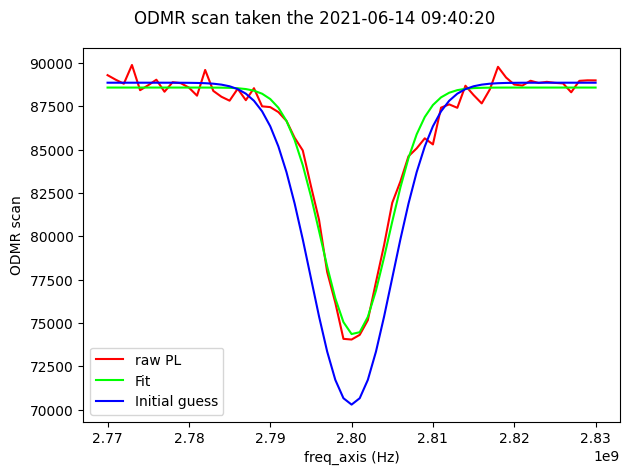

In [6]:
odmr_scan.plot()
plt.tight_layout() # very useful line, to put the title at the right place and plot only once.

Or we can have an interactive plot in a 1D Viewer from PyMoDAQ.

In [7]:
odmr_viewer = Viewer1D(title="ODMR")
odmr_viewer.show_data(odmr_scan)

We need to extract the value of the reference magnetic field, from the result of the fit.

In [9]:
f_ref = fit_result.params['center']
B_bias = (2.87e9-f_ref)/gamma_NV # in T
print(f'The value of the bias field along the NV axis is {B_bias*1e3:.2f} mT.')

The value of the bias field along the NV axis is 2.48 mT.


## Load the full scan
Now we want the real data, corresponding to a scan. Again, everything is stored in text files in this case, a file for each measurement channel, and the metadata is there as a header. 

We start with our specific routine to extract the metadata, we do this on any scan file.

In [10]:
header_content = lqf.load_header_qnami(f'data/{fullb_timestamp}__autosave_QAFM_Height(Sen)_fw.dat')

In [11]:
info, ch_list = lqf.get_metadata_qnami(header_content)

We get a list called `ch_list` of all the measurement channels provided by the instrument: the PL counts, the magnetic field computed by the instrument (not what we want, the reference is not subtracted), the topography, other features from the scanning probe microscope, etc.

In [12]:
print(ch_list)

['counts', 'b_field', 'Height(Sen)', 'Mag', 'Freq']


Once we have this, we can load the data, we know exactly what is stored in the files. The routine below extracts all the available maps and puts them in a DataToExport object.

In [13]:
raw_scan, all_headers, spectra_data = lqf.load_qnami_scan(path, fullb_timestamp, ExperimentType["FullB"])

We can extract some images directly, like the PL or the topography, and plot them in matplotlib figures. We can first get again the list of available channels, but now from the DataToExport object.

In [14]:
print(f'Available channels are: {raw_scan.get_names()}')

Available channels are: ['counts', 'b_field', 'Height(Sen)', 'Mag', 'Freq']


The metadata loaded from the data file is also available there, in the all_headers dict.

In [15]:
pp.pprint(all_headers['counts'])

{'AFM integration time per pixel (s)': 0.1,
 'AFM time for idle move (s)': 0.5,
 'ESR Count Frequency (Hz)': 200.0,
 'ESR Frequency points (#)': 30.0,
 'ESR Frequency start (Hz)': 2770000000.0,
 'ESR Frequency stop (Hz)': 2830000000.0,
 'ESR MW power (dBm)': 24.0,
 'ESR Measurement runs (#)': 20.0,
 'Expect one resonance dip': ' True\n',
 'Measurement parameter list': " ['counts', 'b_field', 'Height(Sen)', 'Mag', "
                               "'Freq']\n",
 'Name of measured signal': ' Fluorescence\n',
 'Optimize Period (s)': 800.0,
 'Parameters for': ' QAFM measurement\n',
 'Total measurement time (s)': 22829.01262,
 'Unit': ' c/s\n',
 'Units of measured signal': ' c/s\n',
 'X image range (m)': 4.999999999999986e-07,
 'X resolution (px)': 80,
 'Y image range (m)': 5.000000000000054e-07,
 'Y resolution (px)': 80,
 'axis name for coord0': ' X\n',
 'axis name for coord1': ' Y\n',
 'coord0_num (#)': 80.0,
 'coord0_start (m)': 4.8e-05,
 'coord0_stop (m)': 4.85e-05,
 'coord1_num (#)': 80.

Let's plot the magnetic field map given by the instrument first.

In [16]:
b_map = raw_scan.get_data_from_name('b_field')

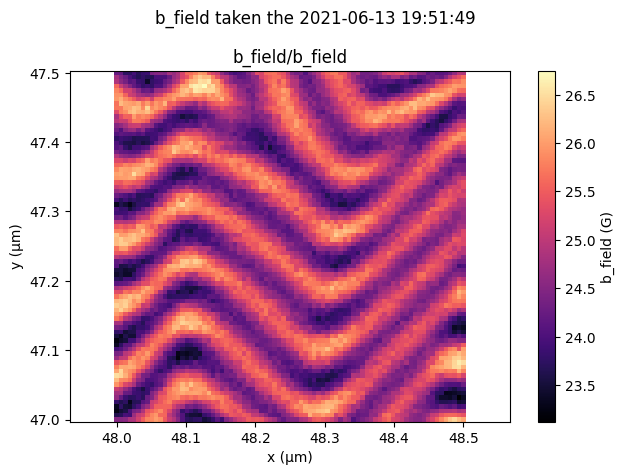

In [17]:
fig = b_map.plot(cmap='magma')
ax = plt.gca()
ax.axis('equal')
plt.colorbar(label=f'{b_map.name} ({b_map.unit.strip()})')
plt.tight_layout()

## Interactive viewers from PyMoDAQ
We can also put everything in a big ViewerDispatcher to explore the data interactively. Our custom version just arranges the viewer differently.

In [18]:
scan_viewer_custom = CustomViewerDispatcher(title="Raw scan") # alternatively: ViewerDispatcher(title="Raw scan")
scan_viewer_custom.show_data(raw_scan)

Idem for the spectra, which are 3D data, one spectrum at each pixel, we can explore them in a NDViewer. The image on the left can display different usefuls things:
* argmin corresponds to a field image
* mean, sum, or max gives a PL image
* while selecting a narrow range on the ODMR, we can get isolines

In [19]:
spectra_viewer = ViewerND(title="Spectra")
spectra_viewer.show_data(spectra_data)

## Fitting the spectra in the scan

Now we would like to fit again the data, with the function we want, etc. We also have a routine for this. This is a little slow, be patient.

In [20]:
fitted_spectra, raw_fitted_scan = sfit.fit_raw_scan(spectra_data, 8e6, 'single_lorentzian', n_jobs=4)

  0%|                                                                                                                                                                  | 0/80 [00:00<?, ?it/s]WARNING:root:Cannot create local config folder at this location: /etc/.pymodaq, try using admin rights. Changing the not permitted path to a user one: /home/aurore/.pymodaq.
INFO:pymodaq:
INFO:pymodaq:
INFO:pymodaq:************************
INFO:pymodaq:Registering Serializables...
INFO:pymodaq:
INFO:pymodaq:
INFO:pymodaq:************************
INFO:pymodaq:Registering Serializables...
INFO:pymodaq:Done
INFO:pymodaq:Done
INFO:pymodaq:************************
INFO:pymodaq:************************
INFO:pymodaq_data:************************
INFO:pymodaq_data:************************
INFO:pymodaq_data:Initializing the pint unit register
INFO:pymodaq_data:Initializing the pint unit register
INFO:pymodaq_data:************************
INFO:pymodaq_data:************************
INFO:pymodaq:
INFO:pymodaq:


We can explore the result of the fits, checking that everything looks correct, again using a ND viewer.

In [21]:
fitted_spectra_viewer = ViewerND(title='Fitted Spectra')
fitted_spectra_viewer.show_data(fitted_spectra)

And now we have a look at all the images generated from the fit.

In [22]:
fitted_scan_viewer = CustomViewerDispatcher(title='Fitted scan')
fitted_scan_viewer.show_data(raw_fitted_scan)

We got really only the raw fit results. For each parameter, we have maps for both the value and the uncertainty, but this is not necessarily the quantities that we are interested in. We sort and convert all this in the physical quantitities we are interested in.

In [23]:
output_maps = ['Linewidth', 'Fitted PL', 'B field', 'Contrast']
treated_scan = sfit.post_treat_fitted_scan(raw_fitted_scan, output_maps, [], all_headers, [f_ref] )

In [24]:
treated_scan_viewer = CustomViewerDispatcher(title="Treated data")
treated_scan_viewer.show_data(treated_scan)

It starts to look nice! Let's extract a line profile from the magnetic field map, to determine the period of the oscillation we observe. This oscillation is the signature of the presence of a magnetic cycloid in this sample (this is an image of bismuth ferrite). 

To extract the profile, we use a ROI (avoid rotating it with pyqtgraph 0.13, this is buggy, but it seems that pyqtgraph 0.14 fixes the issue). If you right click on the ROI, you can 'Copy ROI to clipboard', and this way get the data directly by slicing the map. We also immediately average along an axis to get a smooth profile.

In [25]:
profile = treated_scan.get_data_from_name('B field').isig[(slice(2, 86, None), slice(18, 22, None))].mean(1) # the slices are obtained from the ROI

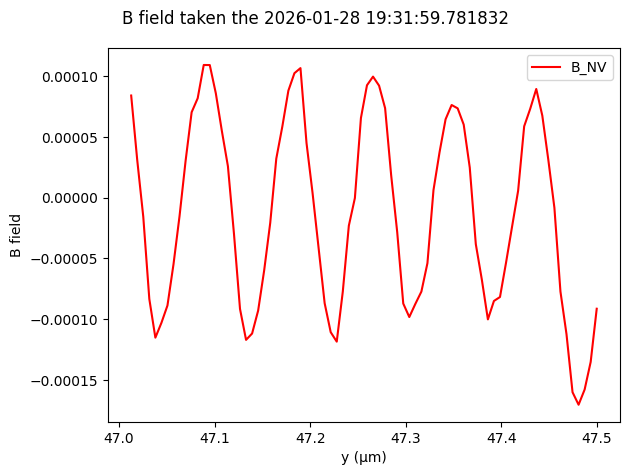

In [26]:
profile.plot();
profile.name = 'BNV profile'
plt.tight_layout()

Let's fit this curve with a sine to get the period.

In [27]:
sine_model = lm.models.SineModel() + lm.models.ConstantModel()
init_guess = {'amplitude': {'value':50}, 'frequency': {'value': (2*np.pi/80e-3)}, 'shift': {'value': 0}, 'c' : {'value': -5}}
params = sine_model.make_params(**init_guess)
y_axis = profile.axes[0].get_data()
y_axis = y_axis - np.min(y_axis)
fit_result = sine_model.fit(profile.data[0]*1e6, params, x=y_axis) #converted in µT

We can append the fit to the DataWithAxes object containing the profile.

In [28]:
profile.append(pyd.DataWithAxes('Fit', source='calculated', data=[fit_result.best_fit*1e-6], labels=['Fit']))


 Field amplitude: 105.9 µT, period: 86.6 nm



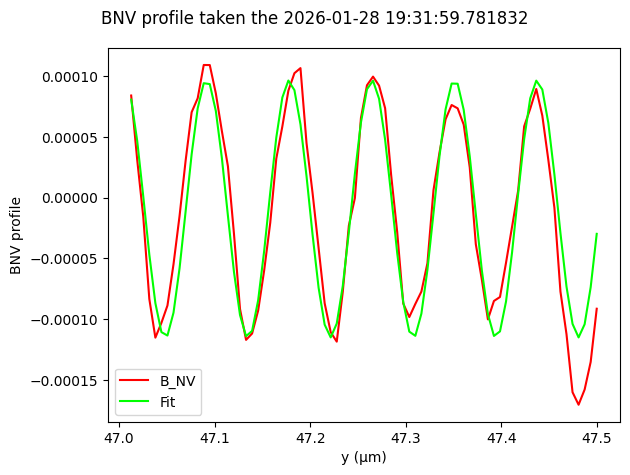

In [29]:
profile.plot()
plt.tight_layout()

print(f'\n Field amplitude: {np.round(fit_result.best_values['amplitude'], 1)} µT, period: {np.round(2e3*np.pi/fit_result.best_values['frequency'], 1)} nm\n')

## Saving data

Now that we did all this, we want to save the analyzed data. We can also use PyMoDAQ for this.

In [30]:
h5saver = H5SaverLowLevel()
h5saver.init_file(Path('awesome_BFO_data.h5'), raw_group_name='AnalyzedData')
h5saver.add_det_group('/AnalyzedData', 'BFO')

/AnalyzedData/Detector002 (GROUP) 'BFO'
  children := []

In [31]:
datasaver = DataToExportSaver(h5saver)
datasaver.add_data('/AnalyzedData/Detector000', treated_scan)

In [ ]:
profilesaver = DataSaverLoader(h5saver)
profilesaver.add_data('/AnalyzedData/Detector000', profile) # new detector?